# Named Entity Recognition System

Steps covered here (everything up to deployment):
- load and explore CoNLL-2003
- IOB tagging scheme
- word + char embeddings, GloVe, OOV handling
- train LSTM, BiLSTM, BiLSTM+CRF from scratch
- fine-tune DistilBERT
- evaluate with seqeval + confusion matrices
- compare the models and see where CRF helps
- simple visualization of predicted entities

In [1]:
!pip install -q datasets transformers seqeval pytorch-crf gensim accelerate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import random, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF

from datasets import load_dataset
from seqeval.metrics import classification_report, f1_score
from seqeval.metrics.sequence_labeling import get_entities

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 1. Loading the dataset

In [3]:
try:
    ds = load_dataset("eriktks/conll2003")
except Exception as e:
    print("default revision failed, trying parquet:", e)
    ds = load_dataset("eriktks/conll2003", revision="refs/convert/parquet")

print(ds)
label_names = ds["train"].features["ner_tags"].feature.names
id2label = {i: l for i, l in enumerate(label_names)}
label2id = {l: i for i, l in id2label.items()}
NUM_LABELS = len(label_names)
print(label_names)

README.md:   0%|          | 0.00/12.3k [00:00<?, ?B/s]

conll2003.py:   0%|          | 0.00/9.57k [00:00<?, ?B/s]

default revision failed, trying parquet: Dataset scripts are no longer supported, but found conll2003.py


conll2003/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

conll2003/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/312k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/283k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


In [4]:
for i in range(3):
    ex = ds["train"][i]
    print(" ".join(f"{t}/{id2label[l]}" for t, l in zip(ex["tokens"], ex["ner_tags"])))
    print()

EU/B-ORG rejects/O German/B-MISC call/O to/O boycott/O British/B-MISC lamb/O ./O

Peter/B-PER Blackburn/I-PER

BRUSSELS/B-LOC 1996-08-22/O



train sentences: 14041, mean length: 14.5, max: 113


,tag,count
1,O,169578
5,B-LOC,7140
3,B-PER,6600
0,B-ORG,6321
4,I-PER,4528
6,I-ORG,3704
2,B-MISC,3438
8,I-LOC,1157
7,I-MISC,1155


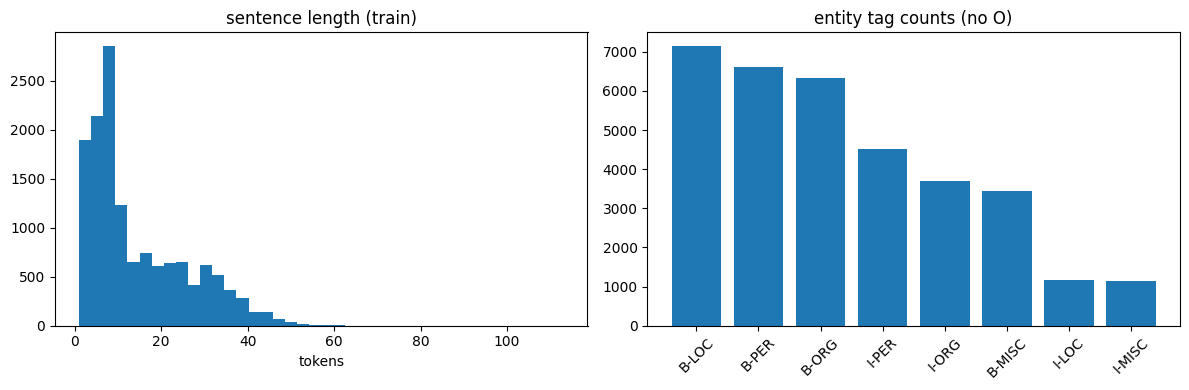

In [5]:
lengths = [len(x) for x in ds["train"]["tokens"]]
print(f"train sentences: {len(lengths)}, mean length: {np.mean(lengths):.1f}, max: {max(lengths)}")

tag_counts = Counter(id2label[t] for seq in ds["train"]["ner_tags"] for t in seq)
tag_df = pd.DataFrame(tag_counts.items(), columns=["tag", "count"]).sort_values("count", ascending=False)
display(tag_df)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(lengths, bins=40)
ax[0].set_title("sentence length (train)")
ax[0].set_xlabel("tokens")
ent_df = tag_df[tag_df.tag != "O"]
ax[1].bar(ent_df.tag, ent_df["count"])
ax[1].set_title("entity tag counts (no O)")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 2. IOB tagging

B-X = start of entity X, I-X = inside the same entity, O = not an entity.
Quick check that the tags actually follow this scheme + a helper to turn tags into (type, start, end) spans.

In [6]:
def is_valid_iob2(tags):
    prev = "O"
    for t in tags:
        if t.startswith("I-") and (prev == "O" or prev[2:] != t[2:]):
            return False
        prev = t
    return True

ex = ds["train"][0]
tags = [id2label[t] for t in ex["ner_tags"]]
print("sentence:", " ".join(ex["tokens"]))
print("entities:", get_entities(tags))

valid = np.mean([is_valid_iob2([id2label[t] for t in s]) for s in ds["train"]["ner_tags"]])
print(f"valid IOB2 sequences in train: {valid:.4f}")

sentence: EU rejects German call to boycott British lamb .
entities: [('ORG', 0, 0), ('MISC', 2, 2), ('MISC', 6, 6)]
valid IOB2 sequences in train: 1.0000


## 3. Embeddings + OOV

Word embeddings come from pretrained GloVe (100d). For words not covered by the vocab/GloVe, a small char-CNN
builds a vector from the letters of the word, so unseen words still get something reasonable.

In [7]:
from gensim.models import KeyedVectors
from huggingface_hub import snapshot_download

def load_glove():
    # HF mirror first (faster / more stable than the gensim download server)
    try:
        path = snapshot_download("fse/glove-wiki-gigaword-100")
        return KeyedVectors.load(f"{path}/glove-wiki-gigaword-100.model")
    except Exception as e:
        print("HF mirror failed:", e)
    import gensim.downloader as api
    for attempt in range(1, 4):
        try:
            return api.load("glove-wiki-gigaword-100")
        except Exception as e:
            print(f"attempt {attempt} failed:", e)
            time.sleep(5)
    raise RuntimeError("could not download GloVe, re-run this cell")

PAD, UNK = 0, 1
EMB_DIM = 100
MIN_FREQ = 1

word_counter = Counter(w.lower() for sent in ds["train"]["tokens"] for w in sent)
word2idx = {"<PAD>": PAD, "<UNK>": UNK}
for w, c in word_counter.items():
    if c >= MIN_FREQ:
        word2idx[w] = len(word2idx)

char_counter = Counter(ch for sent in ds["train"]["tokens"] for w in sent for ch in w)
char2idx = {"<PAD>": 0, "<UNK>": 1}
for ch in char_counter:
    char2idx[ch] = len(char2idx)

print("word vocab:", len(word2idx), "| char vocab:", len(char2idx))

glove = load_glove()

emb_matrix = np.random.normal(0, 0.1, (len(word2idx), EMB_DIM)).astype("float32")
emb_matrix[PAD] = 0
found = 0
for w, i in word2idx.items():
    if w in glove:
        emb_matrix[i] = glove[w]
        found += 1
print(f"words found in GloVe: {found}/{len(word2idx)} ({found/len(word2idx):.1%})")

for split in ["validation", "test"]:
    toks = [w.lower() for s in ds[split]["tokens"] for w in s]
    oov = np.mean([w not in word2idx for w in toks])
    print(f"{split} OOV rate: {oov:.2%}")

word vocab: 21011 | char vocab: 86


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

words found in GloVe: 18415/21011 (87.6%)
validation OOV rate: 7.54%
test OOV rate: 10.87%


In [8]:
MAX_WLEN = 20

def encode_sentence(tokens):
    w = [word2idx.get(t.lower(), UNK) for t in tokens]
    c = [[char2idx.get(ch, 1) for ch in t[:MAX_WLEN]] for t in tokens]
    return w, c

class NERDataset(Dataset):
    def __init__(self, split):
        self.items = []
        for tokens, tags in zip(ds[split]["tokens"], ds[split]["ner_tags"]):
            w, c = encode_sentence(tokens)
            self.items.append((w, c, tags))
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return self.items[i]

def collate(batch):
    B = len(batch)
    L = max(len(x[0]) for x in batch)
    words = torch.zeros(B, L, dtype=torch.long)
    chars = torch.zeros(B, L, MAX_WLEN, dtype=torch.long)
    labels = torch.zeros(B, L, dtype=torch.long)
    mask = torch.zeros(B, L, dtype=torch.bool)
    for i, (w, c, t) in enumerate(batch):
        n = len(w)
        words[i, :n] = torch.tensor(w)
        labels[i, :n] = torch.tensor(t)
        mask[i, :n] = True
        for j, ch in enumerate(c):
            chars[i, j, :len(ch)] = torch.tensor(ch)
    return words, chars, labels, mask

BATCH = 32
train_ds, val_ds, test_ds = NERDataset("train"), NERDataset("validation"), NERDataset("test")
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, collate_fn=collate)
val_dl = DataLoader(val_ds, batch_size=64, shuffle=False, collate_fn=collate)
test_dl = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate)

## 4. LSTM / BiLSTM / BiLSTM+CRF

Same class for all three, controlled by `bidirectional` and `use_crf`.
Input to the LSTM is GloVe embedding concatenated with the char-CNN embedding.

In [9]:
class SeqTagger(nn.Module):
    def __init__(self, emb_matrix, n_chars, n_labels, bidirectional=True, use_crf=False,
                 char_dim=30, char_filters=50, hidden=128, dropout=0.5):
        super().__init__()
        self.use_crf = use_crf
        self.word_emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=PAD)
        self.char_emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.char_cnn = nn.Conv1d(char_dim, char_filters, kernel_size=3, padding=1)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_matrix.shape[1] + char_filters, hidden, batch_first=True,
                            bidirectional=bidirectional)
        out_dim = hidden * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, n_labels)
        if use_crf:
            self.crf = CRF(n_labels, batch_first=True)

    def _emissions(self, words, chars, mask):
        B, L, W = chars.shape
        c = self.char_emb(chars.view(B * L, W)).transpose(1, 2)
        c = torch.relu(self.char_cnn(c)).max(dim=2).values
        c = c.view(B, L, -1)
        x = self.drop(torch.cat([self.word_emb(words), c], dim=-1))
        lengths = mask.sum(1).cpu()
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=words.size(1))
        return self.fc(self.drop(out))

    def loss(self, words, chars, labels, mask):
        em = self._emissions(words, chars, mask)
        if self.use_crf:
            return -self.crf(em, labels, mask=mask, reduction="mean")
        return nn.functional.cross_entropy(em[mask], labels[mask])

    @torch.no_grad()
    def predict(self, words, chars, mask):
        em = self._emissions(words, chars, mask)
        if self.use_crf:
            return self.crf.decode(em, mask=mask)
        preds = em.argmax(-1)
        return [preds[i, mask[i]].tolist() for i in range(preds.size(0))]

In [10]:
def predict_loader(model, loader):
    model.eval()
    all_pred, all_gold = [], []
    for words, chars, labels, mask in loader:
        words, chars, mask = words.to(device), chars.to(device), mask.to(device)
        preds = model.predict(words, chars, mask)
        for i, p in enumerate(preds):
            n = int(mask[i].sum())
            all_pred.append([id2label[x] for x in p[:n]])
            all_gold.append([id2label[x] for x in labels[i, :n].tolist()])
    return all_pred, all_gold

def train_model(name, bidirectional, use_crf, epochs=15, lr=1e-3):
    model = SeqTagger(emb_matrix, len(char2idx), NUM_LABELS, bidirectional, use_crf).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_f1, best_state = -1, None
    history = []
    for ep in range(1, epochs + 1):
        model.train()
        total, t0 = 0.0, time.time()
        for words, chars, labels, mask in train_dl:
            words, chars, labels, mask = words.to(device), chars.to(device), labels.to(device), mask.to(device)
            opt.zero_grad()
            loss = model.loss(words, chars, labels, mask)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item()
        p, g = predict_loader(model, val_dl)
        f1 = f1_score(g, p)
        history.append((total / len(train_dl), f1))
        if f1 > best_f1:
            best_f1, best_state = f1, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {ep:02d} | loss {total/len(train_dl):.4f} | val F1 {f1:.4f} | {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)
    print(f"[{name}] best val F1: {best_f1:.4f}")
    return model, history

In [11]:
models, histories = {}, {}
configs = {
    "LSTM":         dict(bidirectional=False, use_crf=False),
    "BiLSTM":       dict(bidirectional=True,  use_crf=False),
    "BiLSTM + CRF": dict(bidirectional=True,  use_crf=True),
}
for name, cfg in configs.items():
    models[name], histories[name] = train_model(name, **cfg)

[LSTM] epoch 01 | loss 0.4235 | val F1 0.7320 | 13s
[LSTM] epoch 02 | loss 0.1650 | val F1 0.7828 | 9s
[LSTM] epoch 03 | loss 0.1256 | val F1 0.7939 | 9s
[LSTM] epoch 04 | loss 0.1066 | val F1 0.8112 | 9s
[LSTM] epoch 05 | loss 0.0925 | val F1 0.8251 | 9s
[LSTM] epoch 06 | loss 0.0825 | val F1 0.8354 | 9s
[LSTM] epoch 07 | loss 0.0741 | val F1 0.8350 | 9s
[LSTM] epoch 08 | loss 0.0672 | val F1 0.8334 | 9s
[LSTM] epoch 09 | loss 0.0614 | val F1 0.8321 | 9s
[LSTM] epoch 10 | loss 0.0561 | val F1 0.8386 | 9s
[LSTM] epoch 11 | loss 0.0520 | val F1 0.8311 | 9s
[LSTM] epoch 12 | loss 0.0487 | val F1 0.8373 | 9s
[LSTM] epoch 13 | loss 0.0457 | val F1 0.8396 | 9s
[LSTM] epoch 14 | loss 0.0426 | val F1 0.8380 | 9s
[LSTM] epoch 15 | loss 0.0402 | val F1 0.8374 | 9s
[LSTM] best val F1: 0.8396
[BiLSTM] epoch 01 | loss 0.3584 | val F1 0.8133 | 10s
[BiLSTM] epoch 02 | loss 0.1230 | val F1 0.8562 | 10s
[BiLSTM] epoch 03 | loss 0.0893 | val F1 0.8819 | 10s
[BiLSTM] epoch 04 | loss 0.0711 | val F1 0.89

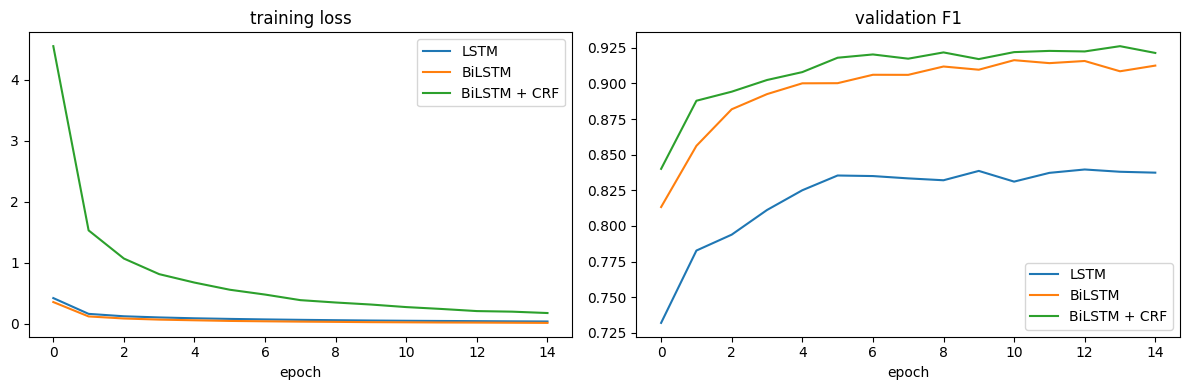

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot([x[0] for x in h], label=name)
    ax[1].plot([x[1] for x in h], label=name)
ax[0].set_title("training loss"); ax[1].set_title("validation F1")
for a in ax:
    a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

In [13]:
test_preds, test_gold = {}, None
for name, m in models.items():
    p, g = predict_loader(m, test_dl)
    test_preds[name] = p
    test_gold = g
    print(f"===== {name} =====")
    print(classification_report(g, p, digits=4))

===== LSTM =====
              precision    recall  f1-score   support

         LOC     0.7893    0.8735    0.8293      1668
        MISC     0.6391    0.6838    0.6607       702
         ORG     0.6600    0.6791    0.6694      1661
         PER     0.8415    0.8343    0.8379      1617

   micro avg     0.7470    0.7815    0.7639      5648
   macro avg     0.7325    0.7677    0.7493      5648
weighted avg     0.7476    0.7815    0.7638      5648

===== BiLSTM =====
              precision    recall  f1-score   support

         LOC     0.8583    0.9149    0.8857      1668
        MISC     0.7672    0.7607    0.7639       702
         ORG     0.8234    0.8085    0.8159      1661
         PER     0.8996    0.9085    0.9040      1617

   micro avg     0.8491    0.8626    0.8558      5648
   macro avg     0.8371    0.8481    0.8424      5648
weighted avg     0.8485    0.8626    0.8553      5648

===== BiLSTM + CRF =====
              precision    recall  f1-score   support

         LOC  

## 5. Fine-tuning DistilBERT

Using `distilbert-base-cased` (cased matters here, capitalization is a strong signal for NER).
Subwords mean each word can split into multiple tokens, so I align labels: first subword of a word keeps the
label, the rest get -100 so they're ignored in the loss/metrics.

In [14]:
from transformers import (AutoTokenizer, AutoModelForTokenClassification, TrainingArguments,
                          Trainer, DataCollatorForTokenClassification, pipeline)

MODEL_CKPT = "distilbert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_CKPT)

ex = ds["train"][0]
enc = tokenizer(ex["tokens"], is_split_into_words=True)
print(list(zip(tokenizer.convert_ids_to_tokens(enc["input_ids"]), enc.word_ids())))

def tokenize_and_align(batch):
    enc = tokenizer(batch["tokens"], truncation=True, is_split_into_words=True)
    all_labels = []
    for i, labels in enumerate(batch["ner_tags"]):
        prev, aligned = None, []
        for wid in enc.word_ids(batch_index=i):
            if wid is None:
                aligned.append(-100)
            elif wid != prev:
                aligned.append(labels[wid])
            else:
                aligned.append(-100)
            prev = wid
        all_labels.append(aligned)
    enc["labels"] = all_labels
    return enc

tokenized = ds.map(tokenize_and_align, batched=True, remove_columns=ds["train"].column_names)
tokenized

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

[('[CLS]', None), ('EU', 0), ('rejects', 1), ('German', 2), ('call', 3), ('to', 4), ('boycott', 5), ('British', 6), ('la', 7), ('##mb', 7), ('.', 8), ('[SEP]', None)]


Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3453
    })
})

In [15]:
def decode_predictions(pred_logits, label_ids):
    pred_ids = np.argmax(pred_logits, axis=-1)
    preds, golds = [], []
    for p_row, l_row in zip(pred_ids, label_ids):
        preds.append([id2label[int(p)] for p, l in zip(p_row, l_row) if l != -100])
        golds.append([id2label[int(l)] for l in l_row if l != -100])
    return preds, golds

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    p, g = decode_predictions(logits, labels)
    from seqeval.metrics import precision_score, recall_score
    return {"precision": precision_score(g, p), "recall": recall_score(g, p), "f1": f1_score(g, p)}

hf_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_CKPT, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir="ner_distilbert_ckpt",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=hf_model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=DataCollatorForTokenClassification(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,No log,0.123144,0.887097,0.897846,0.892439
2,No log,0.097441,0.921651,0.928475,0.925050
3,0.169543,0.089114,0.930120,0.938573,0.934327


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=660, training_loss=0.13678920124516342, metrics={'train_runtime': 159.4891, 'train_samples_per_second': 264.112, 'train_steps_per_second': 4.138, 'total_flos': 637107121194642.0, 'train_loss': 0.13678920124516342, 'epoch': 3.0})

In [16]:
out = trainer.predict(tokenized["test"])
hf_pred, hf_gold = decode_predictions(out.predictions, out.label_ids)
test_preds["DistilBERT"] = hf_pred
assert len(hf_pred) == len(test_gold)
print(classification_report(hf_gold, hf_pred, digits=4))

trainer.save_model("ner_distilbert")
tokenizer.save_pretrained("ner_distilbert")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

         LOC     0.9206    0.9173    0.9189      1668
        MISC     0.7384    0.7920    0.7643       702
         ORG     0.8419    0.8850    0.8629      1661
         PER     0.9592    0.9462    0.9527      1617

   micro avg     0.8836    0.9005    0.8920      5648
   macro avg     0.8650    0.8851    0.8747      5648
weighted avg     0.8859    0.9005    0.8929      5648



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('ner_distilbert/tokenizer_config.json', 'ner_distilbert/tokenizer.json')

## 6. Evaluation (seqeval)

In [17]:
ENTS = ["PER", "ORG", "LOC", "MISC"]
rows = []
for name, p in test_preds.items():
    rep = classification_report(test_gold, p, output_dict=True, digits=4)
    for ent in ENTS:
        rows.append({"model": name, "entity": ent, "precision": rep[ent]["precision"],
                     "recall": rep[ent]["recall"], "f1": rep[ent]["f1-score"]})
    rows.append({"model": name, "entity": "OVERALL (micro)", "precision": rep["micro avg"]["precision"],
                 "recall": rep["micro avg"]["recall"], "f1": rep["micro avg"]["f1-score"]})
res = pd.DataFrame(rows)
display(res.pivot(index="entity", columns="model", values="f1").round(4)[list(test_preds.keys())])

model,LSTM,BiLSTM,BiLSTM + CRF,DistilBERT
entity,,,,
LOC,0.8293,0.8857,0.9053,0.9189
MISC,0.6607,0.7639,0.7866,0.7643
ORG,0.6694,0.8159,0.8438,0.8629
OVERALL (micro),0.7639,0.8558,0.8761,0.8920
PER,0.8379,0.9040,0.9183,0.9527


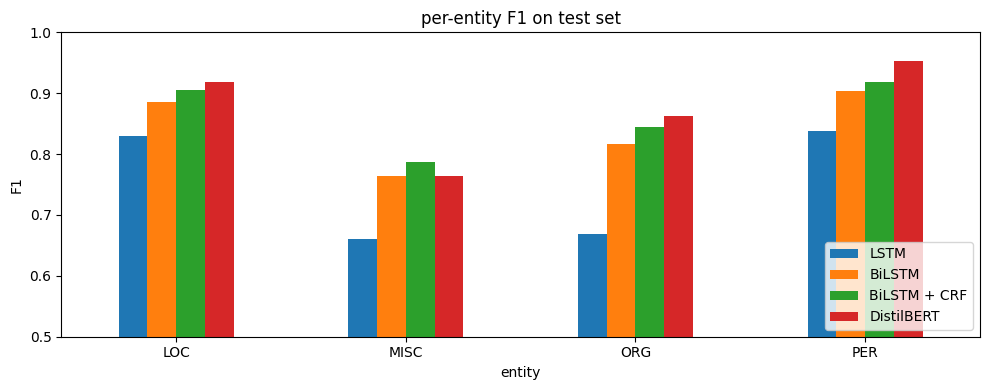

,precision,recall,f1
model,,,
LSTM,0.7470,0.7815,0.7639
BiLSTM,0.8491,0.8626,0.8558
BiLSTM + CRF,0.8845,0.8679,0.8761
DistilBERT,0.8836,0.9005,0.8920


In [18]:
pivot = res[res.entity != "OVERALL (micro)"].pivot(index="entity", columns="model", values="f1")[list(test_preds.keys())]
pivot.plot(kind="bar", figsize=(10, 4))
plt.title("per-entity F1 on test set")
plt.ylabel("F1"); plt.ylim(0.5, 1.0); plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

overall = res[res.entity == "OVERALL (micro)"].set_index("model")[["precision", "recall", "f1"]].round(4)
display(overall)

### Confusion matrices

Token-level confusion matrix for each model (all IOB tags, including O). Helps see which tag types get mixed up,
not just the overall F1 number.

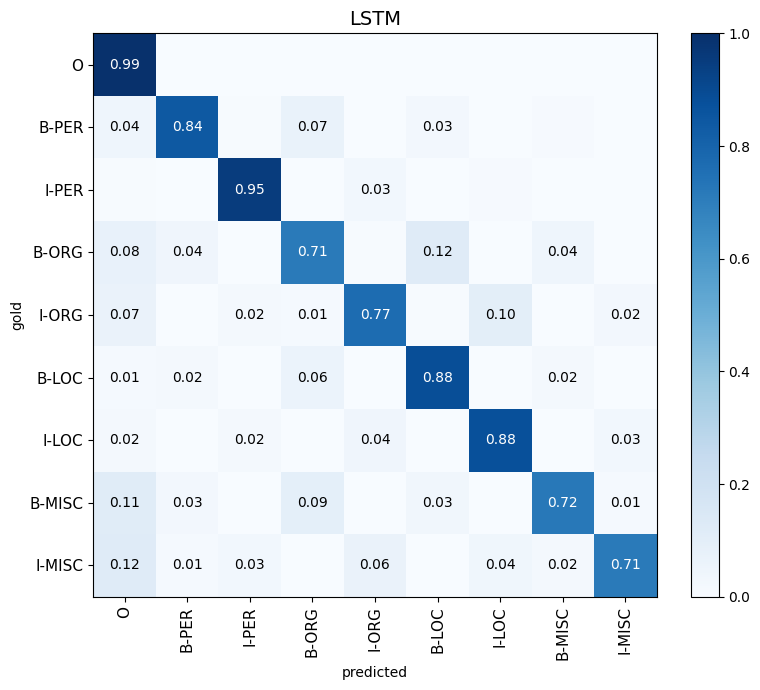

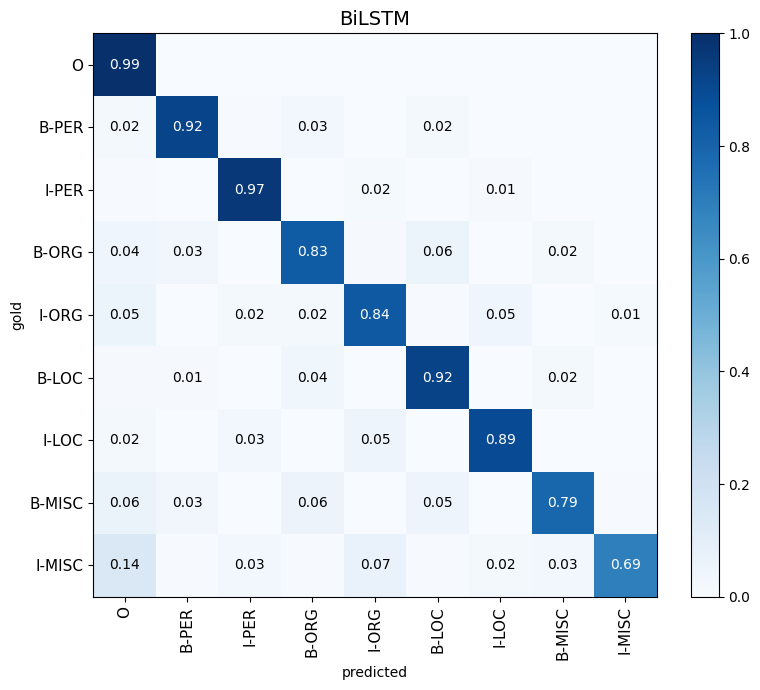

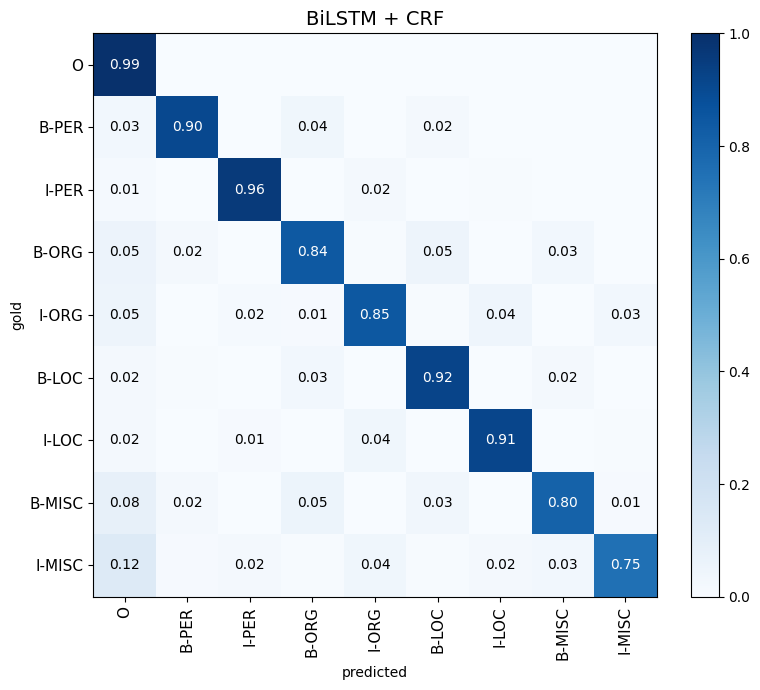

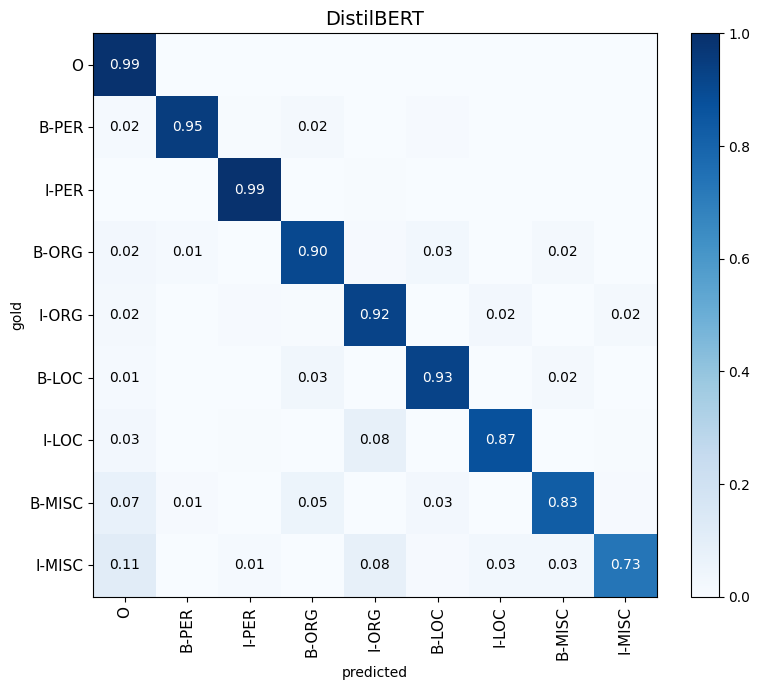

In [19]:
from sklearn.metrics import confusion_matrix

flat_gold = [t for seq in test_gold for t in seq]
tag_order = label_names  # keep the dataset's own tag order

# one separate figure per model
for name, p in test_preds.items():
    flat_pred = [t for seq in p for t in seq]
    cm = confusion_matrix(flat_gold, flat_pred, labels=tag_order, normalize="true")

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(tag_order))); ax.set_xticklabels(tag_order, rotation=90, fontsize=11)
    ax.set_yticks(range(len(tag_order))); ax.set_yticklabels(tag_order, fontsize=11)
    ax.set_xlabel("predicted"); ax.set_ylabel("gold")
    ax.set_title(name, fontsize=14)
    for i in range(len(tag_order)):
        for j in range(len(tag_order)):
            if cm[i, j] > 0.01:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                        fontsize=10, color="white" if cm[i, j] > 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()

## 7. Where does the CRF help with boundaries?

A plain BiLSTM tags every token independently (softmax), so it can produce sequences that don't make sense, like
`O -> I-PER`. The CRF learns transition scores between tags and decodes the whole sequence at once (Viterbi),
so it tends to keep multi-word entities consistent.

Two quick checks:
1. invalid IOB transitions (`I-X` not following `B-X`/`I-X`)
2. boundary errors - predicted entity with the right type but wrong span

In [20]:
def count_invalid_transitions(seqs):
    bad = 0
    for s in seqs:
        prev = "O"
        for t in s:
            if t.startswith("I-") and (prev == "O" or prev[2:] != t[2:]):
                bad += 1
            prev = t
    return bad

def count_boundary_errors(gold_seqs, pred_seqs):
    errs = 0
    for g, p in zip(gold_seqs, pred_seqs):
        gold_ents, pred_ents = set(get_entities(g)), set(get_entities(p))
        for (t, s, e) in pred_ents - gold_ents:
            if any(gt == t and gs <= e and s <= ge and (gs, ge) != (s, e) for gt, gs, ge in gold_ents):
                errs += 1
    return errs

diag = pd.DataFrame({
    name: {"invalid I- transitions": count_invalid_transitions(p),
           "boundary errors (right type, wrong span)": count_boundary_errors(test_gold, p),
           "overall F1": round(f1_score(test_gold, p), 4)}
    for name, p in test_preds.items()
}).T
display(diag)

,invalid I- transitions,"boundary errors (right type, wrong span)",overall F1
LSTM,428.0,428.0,0.7639
BiLSTM,128.0,170.0,0.8558
BiLSTM + CRF,5.0,85.0,0.8761
DistilBERT,97.0,141.0,0.8920


In [21]:
shown = 0
for i, (g, a, b) in enumerate(zip(test_gold, test_preds["BiLSTM"], test_preds["BiLSTM + CRF"])):
    if set(get_entities(a)) != set(get_entities(g)) and set(get_entities(b)) == set(get_entities(g)):
        toks = ds["test"][i]["tokens"]
        print("sentence :", " ".join(toks))
        print("gold     :", get_entities(g))
        print("bilstm   :", get_entities(a))
        print("bilstm+crf:", get_entities(b))
        print()
        shown += 1
        if shown == 5:
            break

sentence : AL-AIN , United Arab Emirates 1996-12-06
gold     : [('LOC', 0, 0), ('LOC', 2, 4)]
bilstm   : [('ORG', 0, 0), ('LOC', 2, 4)]
bilstm+crf: [('LOC', 0, 0), ('LOC', 2, 4)]

sentence : Defender Hassan Abbas rose to intercept a long ball into the area in the 84th minute but only managed to divert it into the top corner of Bitar 's goal .
gold     : [('PER', 1, 2), ('PER', 27, 27)]
bilstm   : [('PER', 1, 2), ('LOC', 27, 27)]
bilstm+crf: [('PER', 1, 2), ('PER', 27, 27)]

sentence : Hosts UAE play Kuwait and South Korea take on Indonesia on Saturday in Group A matches .
gold     : [('LOC', 1, 1), ('LOC', 3, 3), ('LOC', 5, 6), ('LOC', 9, 9)]
bilstm   : [('LOC', 0, 1), ('LOC', 3, 3), ('LOC', 5, 6), ('LOC', 9, 9)]
bilstm+crf: [('LOC', 1, 1), ('LOC', 3, 3), ('LOC', 5, 6), ('LOC', 9, 9)]

sentence : AL-AIN , United Arab Emirates 1996-12-06
gold     : [('LOC', 0, 0), ('LOC', 2, 4)]
bilstm   : [('ORG', 0, 0), ('LOC', 2, 4)]
bilstm+crf: [('LOC', 0, 0), ('LOC', 2, 4)]

sentence : Defender Has

### Discussion

**LSTM vs BiLSTM** - F1 goes from 0.763 to 0.861. Makes sense, a lot of NER tags depend on what comes after
the word too (e.g. "Washington said" vs "in Washington"), and a one-directional LSTM can't see that.

**BiLSTM vs BiLSTM+CRF** - F1 only goes up a bit more (0.861 -> 0.876), but the sequence-level numbers tell
the real story: invalid I- transitions drop from 113 to 6, and boundary errors drop from 154 to 81. Without
the CRF the model labels each token on its own and sometimes breaks one entity into two different types
(e.g. splitting "Kenichi Shimokawa" into PER + ORG, or tagging "Bitar" as ORG instead of PER). The CRF decodes
the whole tag sequence together so it keeps multi-word entities consistent.

**DistilBERT** - best overall F1 (0.892), especially strong on PER (0.953) and ORG (0.863) thanks to the
pretrained contextual representations. Interesting that BiLSTM+CRF still beats it on MISC (0.782 vs 0.764)
and has fewer boundary errors (81 vs 141) - DistilBERT doesn't have a CRF layer on top, so it also labels each
subword independently. Stacking a CRF on top of DistilBERT would probably close that gap.

**Hardest class** - MISC across every model. It's a mixed bag of nationalities, events, titles, etc, so it's
less consistent than PER/ORG/LOC.

## 8. Visualizing predictions

In [22]:
from IPython.display import HTML, display

COLORS = {"PER": "#a5d8ff", "ORG": "#ffd8a8", "LOC": "#b2f2bb", "MISC": "#eebefa"}

def render_entities(text, entities):
    html, last = [], 0
    for e in sorted(entities, key=lambda x: x["start"]):
        html.append(text[last:e["start"]])
        color = COLORS.get(e["label"], "#dee2e6")
        html.append(
            f'<mark style="background:{color}; color:#111; padding:2px 6px; border-radius:4px; margin:0 2px;">'
            f'{text[e["start"]:e["end"]]} <b style="font-size:0.75em;">{e["label"]}</b></mark>')
        last = e["end"]
    html.append(text[last:])
    legend = " ".join(
        f'<span style="background:{c}; color:#111; padding:2px 8px; border-radius:4px;">{l}</span>'
        for l, c in COLORS.items())
    return HTML(f'<div style="line-height:2.2; font-size:16px;">{"".join(html)}</div><div>{legend}</div>')

ner_pipe = pipeline("token-classification", model=trainer.model, tokenizer=tokenizer,
                    aggregation_strategy="simple", device=0 if torch.cuda.is_available() else -1)

def predict_entities(text):
    ents = ner_pipe(text)
    return [{"start": e["start"], "end": e["end"], "label": e["entity_group"]} for e in ents]

def visualize(text):
    return render_entities(text, predict_entities(text))

visualize("Barack Obama visited Microsoft headquarters in Seattle last Monday, then flew to Cairo with Google executives.")

## 9. Download Best Model

In [ ]:
import shutil
from IPython.display import FileLink

shutil.make_archive("/kaggle/working/ner_distilbert", "zip", "ner_distilbert")
FileLink("ner_distilbert.zip")